# Fundamental Analysis Agent — KNN training
Financial Statements of Major Companies (2009–2023). Run from the backend or fundamental_agent folder. This notebook uses the existing project pipeline and overwrites its generated model and reports when run. Labels are rubric-derived, not independent ground truth.

In [1]:
from pathlib import Path
import sys
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'fundamental_agent' / 'config.py').exists()), None)
if root is None:
    raise RuntimeError('Open the notebook inside backend or backend/fundamental_agent')
sys.path.insert(0, str(root))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from fundamental_agent import config as C

In [2]:
import json
from datetime import datetime, timezone

import joblib
import numpy as np
import sklearn
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import (GridSearchCV, LeaveOneGroupOut, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict, cross_validate,
                                     train_test_split)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from fundamental_agent import config as C
from fundamental_agent.features import training_table
from fundamental_agent.preprocess import load_and_clean, report_markdown


def summary(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }

In [3]:
from fundamental_agent.train import metrics_markdown

## 1. Explore the raw dataset

In [4]:
raw = pd.read_csv(C.RAW_CSV)
print('Shape:', raw.shape)
display(raw.head())
display(raw.isna().sum().to_frame('Missing values'))
print('Exact duplicates:', raw.duplicated().sum())
raw.info()

Shape: (161, 23)


,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,EBITDA,Share Holder Equity,...,Current Ratio,Debt/Equity Ratio,ROE,ROA,ROI,Net Profit Margin,Free Cash Flow per Share,Return on Tangible Equity,Number of Employees,Inflation Rate(in US)
0,2022,AAPL,IT,2066.94,394328.0,170782.0,99803.0,6.11,130541.0,50672.0,...,0.8794,2.3695,196.9589,28.2924,66.6994,25.3096,1.3146,196.9589,164000,8.0028
1,2021,AAPL,IT,2913.28,365817.0,152836.0,94680.0,5.61,120233.0,63090.0,...,1.0746,1.9768,150.0713,26.9742,54.9839,25.8818,1.3261,150.0713,154000,4.6979
2,2020,AAPL,IT,2255.97,274515.0,104956.0,57411.0,3.28,77344.0,65339.0,...,1.3636,1.7208,87.8664,17.7256,35.0054,20.9136,1.0183,87.8664,147000,1.2336
3,2019,AAPL,IT,1304.76,260174.0,98392.0,55256.0,2.97,76477.0,90488.0,...,1.5401,1.1940,61.0645,16.3230,30.3113,21.2381,-0.0388,61.0645,137000,1.8122
4,2018,AAPL,IT,748.54,265595.0,101839.0,59531.0,2.98,81801.0,107147.0,...,1.1329,1.0685,55.5601,16.2775,29.6348,22.4142,0.7414,55.5601,132000,2.4426


,Missing values
Year,0
Company,0
Category,0
Market Cap(in B USD),1
Revenue,0
Gross Profit,0
Net Income,0
Earning Per Share,0
EBITDA,0
Share Holder Equity,0


Exact duplicates: 0
<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 23 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Year                                 161 non-null    int64  
 1   Company                              161 non-null    str    
 2   Category                             161 non-null    str    
 3   Market Cap(in B USD)                 160 non-null    float64
 4   Revenue                              161 non-null    float64
 5   Gross Profit                         161 non-null    float64
 6   Net Income                           161 non-null    float64
 7   Earning Per Share                    161 non-null    float64
 8   EBITDA                               161 non-null    float64
 9   Share Holder Equity                  161 non-null    float64
 10  Cash Flow from Operating             161 non-null    float64
 11  Cash Flow from Investin

In [5]:
for d in (C.MODEL_DIR, C.REPORT_DIR, C.DATA_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 1. clean

In [6]:
raw, df, steps = load_and_clean()
df.to_csv(C.CLEAN_CSV, index=False)
(C.REPORT_DIR / "cleaning_report.md").write_text(report_markdown(steps, len(raw), len(df)), encoding="utf-8")

1485

In [7]:
display(pd.DataFrame(steps))
display(df.head())

,check,found,action
0,Column names,1 name(s) with stray spaces: ['Company '],Stripped the spaces
1,Category spelling,"9 labels, 'BANK' and 'Bank' are the same sector",Merged into 'Bank' (8 categories left)
2,Missing values,Market Cap(in B USD): PYPL 2014,Kept as missing. This column is in USD and is ...
3,Duplicate company-year rows,0,-
4,Missing years inside a company's history,none,-
5,"Impossible values (revenue <= 0, gross profit ...",0 row(s),-
6,Stated net margin differs from Net Income / Re...,"5: BCS 2022, BCS 2020, BCS 2019, BCS 2017, BCS...",Kept and flagged. The model recomputes net mar...
7,Stated ROE differs from Net Income / Equity by...,"5: AIG 2010, AIG 2009, SHLDQ 2015, SHLDQ 2014,...",Kept and flagged. ROE is not used as a model f...
8,Negative shareholder equity (ROE and debt-to-e...,"11: SHLDQ 2018, SHLDQ 2017, SHLDQ 2016, SHLDQ ...",Kept. Debt-to-equity is set to the cap of 10 f...
9,Extreme ROE / ROI / return on tangible equity ...,13 row(s),Kept. These three columns are not used as mode...


,Year,Company,Category,Market Cap(in B USD),Revenue,Gross Profit,Net Income,Earning Per Share,EBITDA,Share Holder Equity,...,ROA,ROI,Net Profit Margin,Free Cash Flow per Share,Return on Tangible Equity,Number of Employees,Inflation Rate(in US),flag_margin_mismatch,flag_roe_mismatch,flag_negative_equity
0,2022,AAPL,IT,2066.94,394328.0,170782.0,99803.0,6.11,130541.0,50672.0,...,28.2924,66.6994,25.3096,1.3146,196.9589,164000,8.0028,False,False,False
1,2021,AAPL,IT,2913.28,365817.0,152836.0,94680.0,5.61,120233.0,63090.0,...,26.9742,54.9839,25.8818,1.3261,150.0713,154000,4.6979,False,False,False
2,2020,AAPL,IT,2255.97,274515.0,104956.0,57411.0,3.28,77344.0,65339.0,...,17.7256,35.0054,20.9136,1.0183,87.8664,147000,1.2336,False,False,False
3,2019,AAPL,IT,1304.76,260174.0,98392.0,55256.0,2.97,76477.0,90488.0,...,16.3230,30.3113,21.2381,-0.0388,61.0645,137000,1.8122,False,False,False
4,2018,AAPL,IT,748.54,265595.0,101839.0,59531.0,2.98,81801.0,107147.0,...,16.2775,29.6348,22.4142,0.7414,55.5601,132000,2.4426,False,False,False


## 2. features + labels

In [8]:
t = training_table(df)
X, y, groups = t[C.FEATURES], t["label"], t["Company"]
baseline = y.value_counts(normalize=True).max()

The score awards up to two points for net margin and one each for ROA, operating cash flow margin, current ratio and positive revenue growth. Scores 0–2 are Weak, 3–4 Moderate, and 5–6 Strong. First company-years are excluded because growth is unavailable.

,Company,Year,Category,gross_margin,net_margin,ebitda_margin,ocf_margin,current_ratio,debt_equity,roa,rev_growth,score,label
0,AAPL,2010,IT,39.377539,21.484094,29.761594,28.509007,2.0113,0.0000,18.6385,52.021909,6,Strong
1,AAPL,2011,IT,40.478896,23.946642,32.890835,34.669142,1.6084,0.0000,22.2753,65.962438,6,Strong
2,AAPL,2012,IT,43.871240,26.665091,37.389782,32.494186,1.4958,0.0000,23.7033,44.581474,6,Strong
3,AAPL,2013,IT,37.624481,21.670470,32.623018,31.400152,1.6786,0.1373,17.8923,9.202086,6,Strong
4,AAPL,2014,IT,38.588036,21.614377,33.069285,32.666648,1.0801,0.3164,17.0420,6.953952,6,Strong


label
Strong      93
Moderate    28
Weak        28
Name: count, dtype: int64

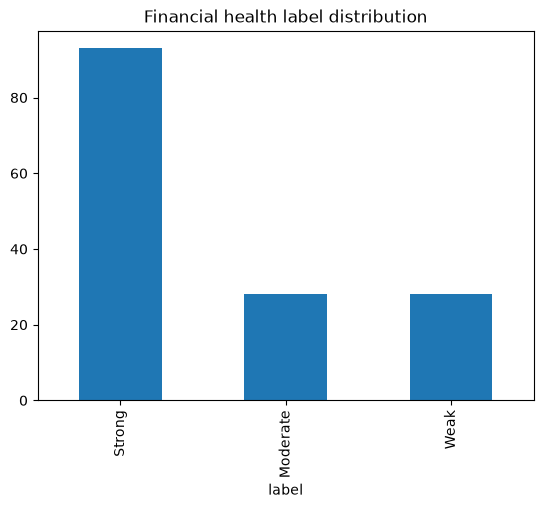

In [9]:
display(t.head())
display(y.value_counts())
y.value_counts().plot.bar(title="Financial health label distribution"); plt.show()

## 3. tune k on the TRAINING part only, then test on the untouched 20 percent

In [10]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=C.RANDOM_STATE)
pipe = make_pipeline(StandardScaler(), KNeighborsClassifier())
grid = GridSearchCV(
    pipe,
    {"kneighborsclassifier__n_neighbors": [1, 3, 5, 7, 9, 11],
     "kneighborsclassifier__weights": ["uniform", "distance"]},
    scoring="f1_macro",
    cv=StratifiedKFold(5, shuffle=True, random_state=C.RANDOM_STATE),
).fit(Xtr, ytr)
k = grid.best_params_["kneighborsclassifier__n_neighbors"]
weights = grid.best_params_["kneighborsclassifier__weights"]
best = grid.best_estimator_

pred = best.predict(Xte)
holdout = summary(yte, pred)
holdout["report"] = classification_report(yte, pred, labels=C.CLASSES, output_dict=True, zero_division=0)
holdout["confusion_matrix"] = confusion_matrix(yte, pred, labels=C.CLASSES).tolist()
holdout["n_train"], holdout["n_test"] = len(Xtr), len(Xte)

In [11]:
print(grid.best_params_)
print(classification_report(yte, pred, zero_division=0))

{'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__weights': 'distance'}
              precision    recall  f1-score   support

    Moderate       0.71      0.83      0.77         6
      Strong       1.00      0.89      0.94        19
        Weak       0.83      1.00      0.91         5

    accuracy                           0.90        30
   macro avg       0.85      0.91      0.87        30
weighted avg       0.92      0.90      0.90        30



## 4. repeated cross-validation on all rows (years of one company can be on both sides)

In [12]:
cv = cross_validate(
    clone(best), X, y,
    cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=C.RANDOM_STATE),
    scoring=["accuracy", "precision_macro", "recall_macro", "f1_macro"],
)
repeated = {m: {"mean": float(cv[f"test_{m}"].mean()), "std": float(cv[f"test_{m}"].std())}
            for m in ("accuracy", "precision_macro", "recall_macro", "f1_macro")}

## 5. leave-one-company-out (the model has never seen the company it is tested on)

In [13]:
loco_pred = cross_val_predict(clone(best), X, y, cv=LeaveOneGroupOut(), groups=groups)
loco = summary(y, loco_pred)
loco["confusion_matrix"] = confusion_matrix(y, loco_pred, labels=C.CLASSES).tolist()
loco["per_company_accuracy"] = {
    c: float((loco_pred[groups == c] == y[groups == c]).mean()) for c in sorted(groups.unique())
}

## 6. final model on all rows, plus what the agent needs for its checks

In [14]:
final = clone(best).fit(X, y)
scaled = final[0].transform(X)
dist, _ = NearestNeighbors(n_neighbors=k + 1).fit(scaled).kneighbors(scaled)
threshold = float(np.percentile(dist[:, k], C.DISTANCE_PERCENTILE))
gate = {"percentile": C.DISTANCE_PERCENTILE, "threshold": threshold,
        "training_rows_rejected": float((dist[:, k] > threshold).mean())}
rejected = []  # how often would the gate reject a company the model has never seen?
for c in groups.unique():
    tr, te = (groups != c).values, (groups == c).values
    sc = StandardScaler().fit(X[tr])
    nn = NearestNeighbors(n_neighbors=k + 1).fit(sc.transform(X[tr]))
    d_tr, _ = nn.kneighbors(sc.transform(X[tr]))
    limit_c = np.percentile(d_tr[:, k], C.DISTANCE_PERCENTILE)
    d_te, _ = nn.kneighbors(sc.transform(X[te]), n_neighbors=k)
    rejected.extend((d_te[:, -1] > limit_c).tolist())
gate["unseen_company_rows_rejected"] = float(np.mean(rejected))

artifact = {
    "pipeline": final,
    "features": C.FEATURES,
    "classes": list(final[-1].classes_),
    "k": int(k),
    "weights": weights,
    "train_stats": {f: {"min": float(X[f].min()), "max": float(X[f].max()),
                        "mean": float(X[f].mean()), "std": float(X[f].std())} for f in C.FEATURES},
    "distance_threshold": threshold,
    "train_rows": t[["Company", "Year", "label"]].to_dict("records"),
    "info": {
        "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "sklearn_version": sklearn.__version__,
        "n_rows": int(len(t)),
        "n_companies": int(groups.nunique()),
        "label_counts": y.value_counts().to_dict(),
    },
}
joblib.dump(artifact, C.MODEL_PATH)

metrics = {
    "dataset": {"rows_clean": int(len(df)), "rows_used": int(len(t)), "companies": int(groups.nunique()),
                "class_counts": y.value_counts().to_dict(), "majority_baseline_accuracy": float(baseline)},
    "chosen_hyperparameters": {"k": int(k), "weights": weights, "scaling": "StandardScaler"},
    "holdout_20_percent": holdout,
    "repeated_5x5_cv": repeated,
    "leave_one_company_out": loco,
    "distance_gate": gate,
}
(C.REPORT_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
(C.REPORT_DIR / "metrics.md").write_text(metrics_markdown(metrics), encoding="utf-8")
display(pd.DataFrame([holdout, loco], index=["Holdout", "Unseen company"])[["accuracy", "precision_macro", "recall_macro", "f1_macro"]])

,accuracy,precision_macro,recall_macro,f1_macro
Holdout,0.900000,0.849206,0.909357,0.874255
Unseen company,0.791946,0.719427,0.647593,0.662779


## Evaluation plots

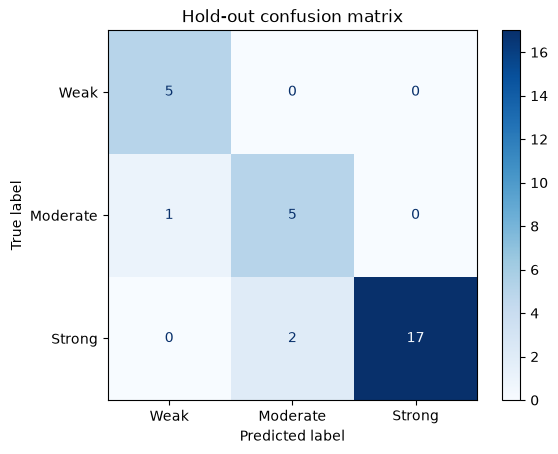

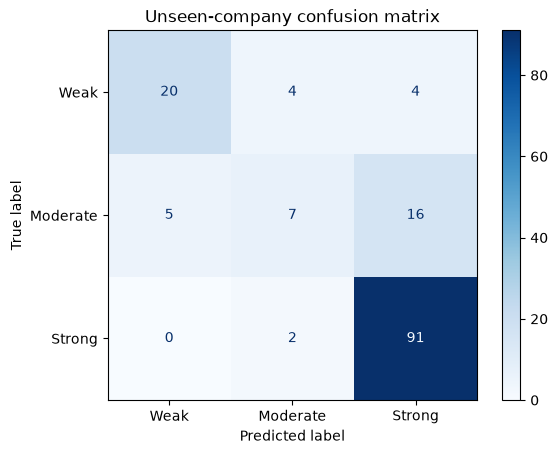

,Holdout,Repeated CV,Unseen company
accuracy,0.900000,0.836368,0.791946
precision_macro,0.849206,0.781136,0.719427
recall_macro,0.909357,0.764897,0.647593
f1_macro,0.874255,0.761300,0.662779


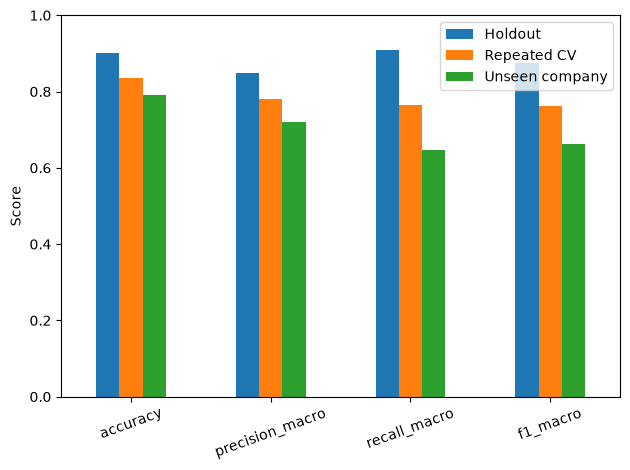

In [15]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(yte, pred, labels=C.CLASSES, cmap='Blues')
plt.title('Hold-out confusion matrix'); plt.show()
ConfusionMatrixDisplay.from_predictions(y, loco_pred, labels=C.CLASSES, cmap='Blues')
plt.title('Unseen-company confusion matrix'); plt.show()
keys = ['accuracy', 'precision_macro', 'recall_macro', 'f1_macro']
results = pd.DataFrame({'Holdout': [holdout[k] for k in keys], 'Repeated CV': [repeated[k]['mean'] for k in keys], 'Unseen company': [loco[k] for k in keys]}, index=keys)
display(results)
results.plot.bar(rot=20, ylim=(0,1)); plt.ylabel('Score'); plt.tight_layout(); plt.show()

## Input validation demo
The existing demo tests valid examples and malformed inputs. Apple FY2022 is a training example, not independent evidence. Yahoo adapter tests use mock data.

In [16]:
import runpy
runpy.run_module("fundamental_agent.demo", run_name="__main__")

1. Apple FY2022 (valid input; note this year is also one of the training rows)
------------------------------------------------------------------------------
Classification: Strong  (confidence 100%, probabilities {'Moderate': 0.0, 'Strong': 1.0, 'Weak': 0.0})
  [revenue_growth] Revenue grew 7.8% year over year, from 365.82B USD to 394.33B USD. That is solid growth.
  [earnings] Net income rose 5.4% to 99.80B USD (previous year 94.68B USD).
  [profitability] Net margin is 25.3%, which is very strong. Gross margin is 43.3% and EBITDA margin 33.1%. Return on assets is 28.3%.
  [cash_flow] Operating cash flow is 31.0% of revenue, so cash generation supports the reported profit.
  [liquidity] The current ratio is 0.88, which is below 1, so short-term obligations exceed short-term assets.
  [leverage] Debt-to-equity is 2.37, which is high.
  [overall] Overall financial condition: Strong. 7 of the 7 most similar company-years in the training data were Strong. Closest matches: AAPL 2022 (Stro

{'__name__': '__main__',
 '__file__': 'c:\\Users\\MEAGAN JANICE DSOUZA\\Desktop\\MULTI-AGENT STOCK RESEARCH ANALYST\\backend\\fundamental_agent\\demo.py',
 '__cached__': 'c:\\Users\\MEAGAN JANICE DSOUZA\\Desktop\\MULTI-AGENT STOCK RESEARCH ANALYST\\backend\\fundamental_agent\\__pycache__\\demo.cpython-314.pyc',
 '__doc__': 'Run:  python -m fundamental_agent.demo\nShows one good analysis and the error notices for bad input. Also acts as a self-test.',
 '__loader__': <_frozen_importlib_external.SourceFileLoader at 0x2cbfebaf830>,
 '__package__': 'fundamental_agent',
 '__spec__': ModuleSpec(name='fundamental_agent.demo', loader=<_frozen_importlib_external.SourceFileLoader object at 0x000002CBFEBAF830>, origin='c:\\Users\\MEAGAN JANICE DSOUZA\\Desktop\\MULTI-AGENT STOCK RESEARCH ANALYST\\backend\\fundamental_agent\\demo.py'),
 '__builtins__': {'__name__': 'builtins',
  '__doc__': "Built-in functions, types, exceptions, and other objects.\n\nThis module provides direct access to all 'built-

## Limitations
The dataset is small and rubric labels are derived from model features. Random splits can share companies between train and test. The company-held-out evaluation uses hyperparameters selected on the row-level training split, so it is not fully nested group validation. Accuracy measures agreement with the rubric, not future stock performance. No live Yahoo verification is performed by this notebook.